[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JoseGG8/AutoEncoderPi/blob/main/modelo/C3/Refinamiento_c3.ipynb)

# 🔬 Refinamiento del Circuito C3 (StronglyEntangling) — Autoencoder Cuántico (QAE)
### Dataset Paderborn | Detección de Fallas en Rodamientos | Paradigma One-Class

---

## ¿Qué hace este notebook?
Compara el **C3 base** (StronglyEntanglingLayers, 2 capas, 1 trash) contra un **C3 refinado** cuya configuración
(capas, trash qubits, rangos de entrelazamiento, compuerta entrelazante, épocas, etc.) se obtiene con una **búsqueda en etapas** (sección 9).
Para cada circuito calcula:
- **Profundidad y ancho** (complejidad)
- **Visualización del circuito** con `qml.draw_mpl`
- **Curva de convergencia** (fidelidad vs época)
- **Error de reconstrucción** (fidelidad del trash qubit + MSE proxy)

---

## Arquitectura del QAE

```
|ψ_in⟩ (7 qubits, 128 amplitudes)
        │
   ┌────▼────────────────┐
   │   Ansätz  U(θ)      │  ← compuertas parametrizadas (se entrenan)
   └────┬──────────┬─────┘
        │          │
   K latentes   M trash qubits
   (info útil)  └─→ P(|0⟩) = Fidelidad
                    1 - F  = info perdida
```

---

## 📖 Glosario de Compuertas Cuánticas

| Compuerta | Qué hace | Params |
|-----------|----------|--------|
| **RY(θ)** | Rota en eje Y → cambia la **probabilidad** de medir \|0⟩ vs \|1⟩ | 1 |
| **RX(θ)** | Rota en eje X → similar a RY en dirección perpendicular | 1 |
| **RZ(φ)** | Rota en eje Z → cambia la **fase** (interferencia), no las probabilidades | 1 |
| **Rot(φ,θ,ω)** | = RZ·RY·RZ → rotación **arbitraria completa** en la esfera de Bloch | 3 |
| **H** | Hadamard → crea superposición 50-50: \|0⟩→(\|0⟩+\|1⟩)/√2 | 0 |
| **CNOT** | Si control=\|1⟩ aplica NOT al objetivo → **crea entrelazamiento** | 0 |
| **CZ** | Si ambos=\|1⟩ aplica fase -1 → más nativo en hardware superconductor | 0 |
| **IsingZZ(J)** | e^{-iJ·ZZ/2} → acoplamiento magnético cuántico entre vecinos | 1 |
| **IsingXX(J)** | e^{-iJ·XX/2} → acoplamiento en eje X, complementa al ZZ | 1 |


In [ ]:
# Instalar PennyLane si es necesario (descomenta en Colab)
#pip install pennylane -q


In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')

from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import train_test_split

import pennylane as qml
from pennylane import numpy as pnp

plt.style.use('seaborn-v0_8-whitegrid'
              if 'seaborn-v0_8-whitegrid' in plt.style.available else 'ggplot')
plt.rcParams.update({'figure.figsize': (12, 5), 'font.size': 11})
COLORES = ['#e74c3c','#3498db','#2ecc71','#f39c12','#9b59b6','#1abc9c','#e67e22']

print(f'PennyLane v{qml.__version__}')


PennyLane v0.45.1


---
## 📦 1. Carga y Preprocesamiento (reutilizado del pipeline principal)

Pipeline: **RobustScaler → Zero-Padding 128 dims → Normalización L₂**
División: **70% train / 15% val / 15% test** (fit del scaler solo en train)


In [2]:
# Rutas posibles (local y Colab)
RUTAS = [
    '../../paderborn_features_tratadas.csv',
    '../paderborn_features_tratadas.csv',
    'paderborn_features_tratadas.csv',
    '/content/paderborn_features_tratadas.csv',
    os.path.abspath(os.path.join(os.getcwd(), '..', '..', 'paderborn_features_tratadas.csv')),
]

ruta = next((r for r in RUTAS if os.path.exists(r)), None)
if ruta is None:
    raise FileNotFoundError('No se encontró paderborn_features_tratadas.csv')

df = pd.read_csv(ruta)
col_label   = 'Label' if 'Label' in df.columns else df.columns[-1]
feature_cols = [c for c in df.columns if c != col_label]
print(f'Dataset: {df.shape[0]} filas x {len(feature_cols)} features | {ruta}')

# ── Partición 70/15/15 ────────────────────────────────────────────────────
X_all = df[feature_cols].values
X_tr, X_tmp = train_test_split(X_all, test_size=0.30, random_state=42)
X_val, X_te = train_test_split(X_tmp, test_size=0.50, random_state=42)

# ── RobustScaler: fit SOLO en train (evita data leakage) ─────────────────
scaler = RobustScaler()   # Usa mediana e IQR → resistente a outliers
scaler.fit(X_tr)          # Aprende estadísticas solo de los datos de entrenamiento
X_tr  = scaler.transform(X_tr)
X_val = scaler.transform(X_val)
X_te  = scaler.transform(X_te)

# ── Zero-Padding a 128 dims (2^7 para Amplitude Encoding en 7 qubits) ────
def zero_pad(X, dim=128):
    """Extiende con ceros a la derecha hasta 'dim' dimensiones."""
    pad = dim - X.shape[1]
    return np.hstack([X, np.zeros((len(X), pad))]) if pad > 0 else X

X_tr  = zero_pad(X_tr);  X_val = zero_pad(X_val);  X_te = zero_pad(X_te)

# ── Normalización L2 por fila (condición cuántica: suma |a_i|^2 = 1) ──────
def l2(X):
    n = np.linalg.norm(X, axis=1, keepdims=True)
    return X / np.where(n == 0, 1.0, n)  # Evita dividir por cero

X_train_q = l2(X_tr)
X_val_q   = l2(X_val)
X_test_q  = l2(X_te)

print(f'Train: {X_train_q.shape} | Val: {X_val_q.shape} | Test: {X_test_q.shape}')
print(f'Norma L2 media (debe ser ≈1): {np.linalg.norm(X_train_q, axis=1).mean():.6f}')


Dataset: 59867 filas x 71 features | ../../paderborn_features_tratadas.csv
Train: (41906, 128) | Val: (8980, 128) | Test: (8981, 128)
Norma L2 media (debe ser ≈1): 1.000000


---
## ⛛️ 2. Circuito C3 y su versión refinada

| Nombre | Idea central | Parámetros ajustables |
|--------|--------------|-----------------------|
| **C3-base** | `StronglyEntanglingLayers` por defecto: Rot por qubit + CNOT de alcance `r = (l mod 6) + 1` | 2 capas, 1 trash (referencia) |
| **C3-ref** | Mismo template, configurable vía `C3_CONFIG` | `n_layers`, `trash`, `ranges`, `imprimitive`, `epochs`, `lr`, `n_samp` |

- `ranges`: `'default'` (el de PennyLane), `'ring'` (todos r=1, vecinos), `'alt'` (r alterna 1 y 3), `'skip2'` (todos r=2).
- `imprimitive`: `'cnot'` o `'cz'`.
- Con `ranges='default'` y `imprimitive='cnot'`, C3 es **estructuralmente idéntico** al C1 refinado (Rot + CNOT de alcance variable); la diferencia del refinamiento de C3 está en la búsqueda sistemática de hiperparámetros y variantes de entrelazamiento.


In [3]:
# ==============================================================================
# CELDA 3: DEFINICIÓN DE C3 (BASE Y REFINADO)
# ==============================================================================
TOTAL_QUBITS = 7  # 2^7 = 128 amplitudes

# ── C3-base: StronglyEntanglingLayers por defecto ───────────────────────────────
def ansatz_c3(weights, wires):
    """
    StronglyEntanglingLayers (template PennyLane).
    Rot(φ,θ,ω) = RZ·RY·RZ (3 params/qubit) + CNOT con patrón variable.
    Crea correlaciones no-locales: qubits no adyacentes quedan entrelazados.
    weights shape: (n_layers, n_wires, 3)
    """
    qml.StronglyEntanglingLayers(weights, wires=wires)  # Rot + CNOT pattern

def ws_c3(nl, nw): return (nl, nw, 3)  # 3 params/qubit/capa

# ── C3-refinado: mismo template con rangos / compuerta entrelazante configurables ─
IMPRIMITIVAS = {'cnot': qml.CNOT, 'cz': qml.CZ}

def resolver_ranges(ranges, n_layers):
    """Convierte un preset en la secuencia de rangos (una por capa) que pide PennyLane.
    None -> patron por defecto de PennyLane: r_l = (l mod (n-1)) + 1."""
    if ranges in (None, 'default'): return None
    if ranges == 'ring':  return [1] * n_layers                                   # vecinos
    if ranges == 'alt':   return [1 if l % 2 == 0 else 3 for l in range(n_layers)]  # corto/largo
    if ranges == 'skip2': return [2] * n_layers                                   # saltos de 2
    return list(ranges)                                                           # lista explicita

def hacer_ansatz_c3(ranges='default', imprimitive='cnot'):
    imp = IMPRIMITIVAS[imprimitive]
    def ansatz(weights, wires):
        rg = resolver_ranges(ranges, weights.shape[0])
        qml.StronglyEntanglingLayers(weights, wires=wires, ranges=rg, imprimitive=imp)
    def ws(nl, nw): return (nl, nw, 3)
    return ansatz, ws

# >>> CONFIGURACION ELEGIDA PARA C3-ref (la celda 13d imprime el bloque a pegar aqui) <<<
# Punto de partida = mejor config encontrada para C1 (equivalente estructural).
C3_CONFIG = dict(n_layers=6, trash=2, ranges='default', imprimitive='cnot',
                 epochs=20, lr=0.12, n_samp=100, batch=25)

ansatz_c3r, ws_c3r = hacer_ansatz_c3(C3_CONFIG['ranges'], C3_CONFIG['imprimitive'])

# ── Registro de circuitos ─────────────────────────────────────────────────────
N_BASE = 'C3-base: StronglyEntangling'
N_REF  = 'C3-ref: StronglyEntangling refinado'
CIRCUITOS = [
    (N_BASE, ansatz_c3,  ws_c3),
    (N_REF,  ansatz_c3r, ws_c3r),
]

# Overrides de entrenamiento por circuito (los demas usan CFG de la celda 8)
CFG_POR_CIRCUITO = {
    N_BASE: dict(n_layers=2, trash=1),
    N_REF:  {k: C3_CONFIG[k] for k in ('n_layers', 'trash', 'epochs', 'lr', 'n_samp', 'batch')},
}

print('Circuitos registrados:')
for nombre, _, wsfn in CIRCUITOS:
    nl = CFG_POR_CIRCUITO[nombre]['n_layers']
    s = wsfn(nl, TOTAL_QUBITS)
    print(f'  {nombre:<38} capas={nl} trash={CFG_POR_CIRCUITO[nombre]["trash"]} '
          f'shape={str(s):<14} params={int(np.prod(s))}')


Circuitos registrados:
  C3-base: StronglyEntangling            capas=2 trash=1 shape=(2, 7, 3)      params=42
  C3-ref: StronglyEntangling refinado    capas=6 trash=2 shape=(6, 7, 3)      params=126


---
## 📐 3. Profundidad, Ancho y Complejidad de cada Circuito

| Métrica | Descripción |
|---------|-------------|
| **Profundidad** | Capas secuenciales máximas. Mayor = más expresivo pero más ruido en hardware |
| **Ancho** | Número de qubits (siempre 7 aquí) |
| **Nº parámetros** | Parámetros entrenables (equivalente a los pesos de una red neuronal) |
| **Total puertas** | Operaciones cuánticas aplicadas |


In [4]:
# ==============================================================================
# CELDA 4: MÉTRICAS DE COMPLEJIDAD — qml.specs()
# ==============================================================================

def calcular_metricas(nombre, ansatz_fn, ws_fn, n_layers=2, n_wires=7, trash=1):
    """Extrae profundidad, numero de puertas y params usando qml.specs().

    Compatibilidad: qml.specs() devuelve un objeto 'resources' cuya API
    varía entre versiones de PennyLane. Aquí se accede de forma defensiva.
    """
    dev_t = qml.device('default.qubit', wires=n_wires)
    tw    = list(range(n_wires - trash, n_wires))
    shape = ws_fn(n_layers, n_wires)
    w0    = np.zeros(shape)                                      # Pesos dummy (estructura)
    sv0   = np.ones(2**n_wires) / np.sqrt(2**n_wires)           # Estado uniforme de referencia
    n_par = int(np.prod(shape))                                  # Total parámetros entrenables

    @qml.qnode(dev_t)
    def circ(sv, w):
        qml.AmplitudeEmbedding(sv, wires=range(n_wires), normalize=False)
        ansatz_fn(w, wires=range(n_wires))
        return qml.probs(wires=tw)

    specs = qml.specs(circ)(sv0, w0)
    res   = specs['resources']

    # ── Profundidad: capas secuenciales máximas ───────────────────────────────
    depth = res.depth

    # ── Total de puertas: compatible con distintas versiones de PennyLane ────
    # Versiones antiguas: res.num_gates (int)
    # Versiones nuevas:   res.gate_sizes (dict {n_qubits: count}) o res.gate_types
    if hasattr(res, 'num_gates'):
        total_gates = res.num_gates
    elif hasattr(res, 'gate_sizes'):
        total_gates = sum(res.gate_sizes.values())  # Suma todos los tamaños de puerta
    else:
        total_gates = sum(res.gate_types.values())  # Alternativa: suma por tipo

    return {
        'Circuito':       nombre,
        'Profundidad':    depth,
        'Ancho (qubits)': n_wires,          # Fijo = 7 en este proyecto
        'Nº Parámetros':  n_par,
        'Total Puertas':  total_gates,
        'Línea Base (%)': round(100.0 / (2**trash), 1),
    }

np.random.seed(0)
tabla_comp = [calcular_metricas(n, fn, ws, n_layers=CFG_POR_CIRCUITO[n]['n_layers'], trash=CFG_POR_CIRCUITO[n]['trash'])
             for n, fn, ws in CIRCUITOS]
df_comp    = pd.DataFrame(tabla_comp).set_index('Circuito')

print(df_comp.to_string())


                                     Profundidad  Ancho (qubits)  Nº Parámetros  Total Puertas  Línea Base (%)
Circuito                                                                                                      
C3-base: StronglyEntangling                    2               7             42              2            50.0
C3-ref: StronglyEntangling refinado            2               7            126              2            25.0


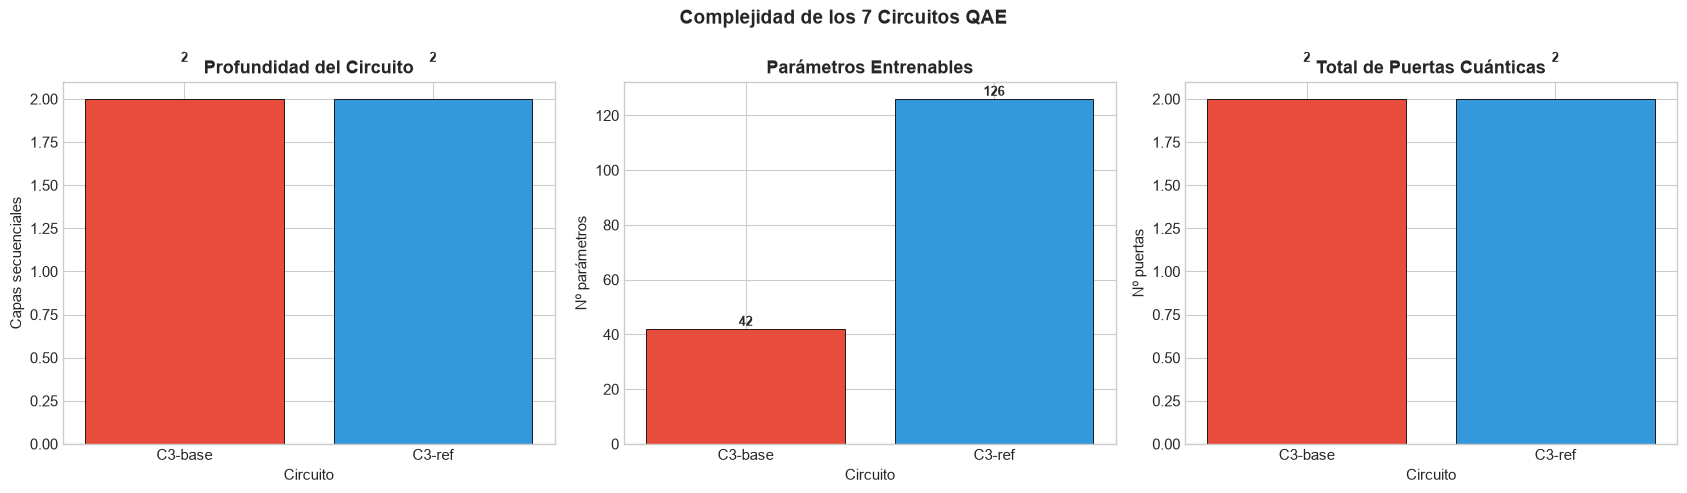

Guardado: complejidad_circuitos.png


In [5]:
# ==============================================================================
# CELDA 5: GRÁFICA — PROFUNDIDAD, PARÁMETROS Y PUERTAS POR CIRCUITO
# ==============================================================================

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
fig.suptitle('Complejidad de los 7 Circuitos QAE', fontsize=14, fontweight='bold')

etiq = [n.split(':')[0] for n in df_comp.index]  # C1, C2, ...
metr = ['Profundidad', 'Nº Parámetros', 'Total Puertas']
tits = ['Profundidad del Circuito', 'Parámetros Entrenables', 'Total de Puertas Cuánticas']
ylabs = ['Capas secuenciales', 'Nº parámetros', 'Nº puertas']

for ax, col, tit, yl in zip(axes, metr, tits, ylabs):
    bars = ax.bar(etiq, df_comp[col], color=COLORES, edgecolor='black', linewidth=0.6)
    ax.set_title(tit, fontweight='bold')
    ax.set_ylabel(yl)
    ax.set_xlabel('Circuito')
    for b in bars:
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.2,
                str(int(b.get_height())), ha='center', va='bottom', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.savefig('complejidad_circuitos.png', dpi=150, bbox_inches='tight')
plt.show()
print('Guardado: complejidad_circuitos.png')


---
## 🖼️ 4. Diagrama de cada Circuito

Cada línea horizontal = un qubit. Las cajas = compuertas. Las líneas verticales = entrelazamiento (CNOT, CZ, Ising...).

> Visualización con 2 capas y 7 qubits (1 trash qubit, K=6 latentes).


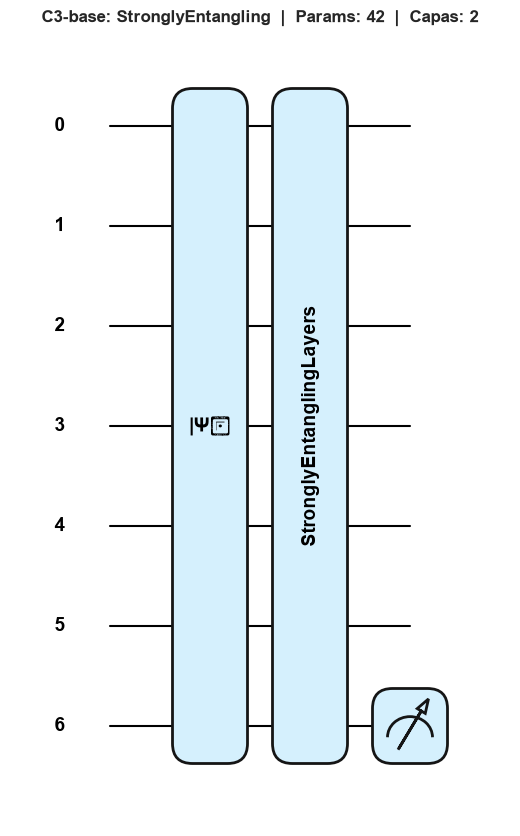

  Guardado: circuito_1_C3-base.png


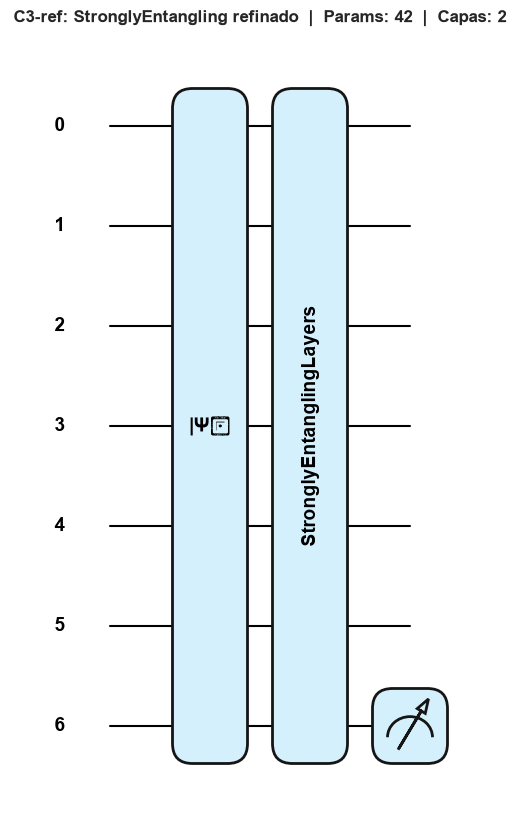

  Guardado: circuito_2_C3-ref.png


In [6]:
# ==============================================================================
# CELDA 6: DIAGRAMAS DE CIRCUITO CON qml.draw_mpl()
# ==============================================================================

NL_VIZ, NW_VIZ, TR_VIZ = 2, 7, 1
np.random.seed(0)
sv_viz = np.ones(2**NW_VIZ) / np.sqrt(2**NW_VIZ)  # Estado uniforme de demo
tw_viz = list(range(NW_VIZ - TR_VIZ, NW_VIZ))

for idx, (nombre, ansatz_fn, ws_fn) in enumerate(CIRCUITOS):
    shape  = ws_fn(NL_VIZ, NW_VIZ)
    w_viz  = np.zeros(shape)
    dev_v  = qml.device('default.qubit', wires=NW_VIZ)

    @qml.qnode(dev_v)
    def circ_viz(sv, w, afn=ansatz_fn, tw=tw_viz, nw=NW_VIZ):
        qml.AmplitudeEmbedding(sv, wires=range(nw), normalize=False)
        afn(w, wires=range(nw))
        return qml.probs(wires=tw)

    fig, ax = qml.draw_mpl(circ_viz, style='pennylane')(sv_viz, w_viz)
    n_par   = int(np.prod(shape))
    fig.suptitle(f'{nombre}  |  Params: {n_par}  |  Capas: {NL_VIZ}',
                 fontsize=12, fontweight='bold', y=1.02)
    plt.tight_layout()
    fname = f'circuito_{idx+1}_{nombre.split(":")[0]}.png'
    fig.savefig(fname, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'  Guardado: {fname}')


---
## 🏋️ 5. Entrenamiento Comparativo

Condiciones iguales para todos:
- **100 registros** de entrenamiento (Fase 1 — prototipo)
- **20 épocas**, batch 25, Adam lr=0.12
- **1 trash qubit** (K=6 latentes, línea base aleatoria = 50%)

> ⚠️ En CPU puede tardar varios minutos. En Google Colab con GPU es mucho más rápido.

### Función de costo
$$\mathcal{L}(\theta) = 1 - \mathbb{E}[P(|0\rangle^M_{\text{trash}})]$$

El objetivo es **maximizar la fidelidad** — que los trash qubits vuelvan a |0⟩,
lo que significa que TODA la info relevante quedó en los K qubits latentes.


In [7]:
# ==============================================================================
# CELDA 7: FUNCIÓN DE ENTRENAMIENTO REUTILIZABLE
# ==============================================================================

def entrenar_qae(nombre, ansatz_fn, ws_fn, X_tr, X_val,
                 n_layers=2, n_wires=7, trash=1,
                 epochs=20, batch=25, lr=0.12, n_samp=100, seed=42):
    """
    Entrena un QAE y devuelve historial de pérdidas/fidelidades.

    Retorna dict con: weights, qnode, fidelidad_fn, history, linea_base, n_params
    """
    np.random.seed(seed)
    dev   = qml.device('default.qubit', wires=n_wires)  # Simulador clásico de qubits
    tw    = list(range(n_wires - trash, n_wires))        # Índices de trash qubits
    shape = ws_fn(n_layers, n_wires)

    # Pesos iniciales aleatorios en [0, 2π] — requires_grad activa el cálculo de gradientes
    W = pnp.random.uniform(0.0, 2*np.pi, size=shape, requires_grad=True)

    @qml.qnode(dev)
    def qnode(sv, w):
        qml.AmplitudeEmbedding(sv, wires=range(n_wires), normalize=False)
        # AmplitudeEmbedding: codifica el vector clásico normalizado como estado cuántico
        ansatz_fn(w, wires=range(n_wires))   # Aplica el circuito variacional
        return qml.probs(wires=tw)            # P de cada estado posible en los trash qubits

    fid   = lambda sv, w: float(qnode(sv, w)[0])  # F = P(|0>) en trash

    def loss_b(w, B):
        return 1.0 - pnp.mean(qnode(B, w)[:, 0])  # 1 - F media (batch vectorizado, ~10x mas rapido)

    X_demo = X_tr[:n_samp]
    opt    = qml.AdamOptimizer(stepsize=lr)  # Adam cuántico de PennyLane
    hist   = {'loss':[], 'fid_tr':[], 'fid_val':[]}
    lb     = 100.0 / (2**trash)

    print(f'\n[{nombre}]  params={int(np.prod(shape))}  trash={trash}  base={lb:.0f}%')

    for ep in range(epochs):
        perm = np.random.permutation(len(X_demo))
        ep_loss = []
        for i in range(0, len(X_demo), batch):
            B = X_demo[perm[i:i+batch]]
            W, cost = opt.step_and_cost(lambda w: loss_b(w, B), W)
            # step_and_cost: calcula gradiente y actualiza pesos en un solo paso
            ep_loss.append(float(cost))
        avg_l   = float(np.mean(ep_loss))
        fid_val = float(np.mean([fid(sv, W) for sv in X_val[:15]])) * 100
        hist['loss'].append(avg_l)
        hist['fid_tr'].append((1-avg_l)*100)
        hist['fid_val'].append(fid_val)
        if (ep+1) % 5 == 0 or ep == 0:
            print(f'  ep {ep+1:02d} | loss={avg_l:.4f} | '
                  f'train={hist["fid_tr"][-1]:.1f}% | val={fid_val:.1f}%')

    print(f'  Final → train={hist["fid_tr"][-1]:.1f}%  val={hist["fid_val"][-1]:.1f}%')
    return dict(nombre=nombre, weights=W, qnode=qnode, fid=fid,
                history=hist, lb=lb, n_params=int(np.prod(shape)), trash=trash)


In [8]:
# ==============================================================================
# CELDA 8: ENTRENAR C3-base Y C3-ref
# ==============================================================================
CFG = dict(n_layers=2, n_wires=7, trash=1, epochs=20,
           batch=25, lr=0.12, n_samp=100, seed=42)
# CFG_POR_CIRCUITO se define en la celda 3 (a partir de C3_CONFIG).

resultados = {}
for nombre, afn, wsfn in CIRCUITOS:
    cfg = {**CFG, **CFG_POR_CIRCUITO.get(nombre, {})}
    resultados[nombre] = entrenar_qae(nombre, afn, wsfn, X_train_q, X_val_q, **cfg)

print('\nEntrenamiento completo.')



[C3-base: StronglyEntangling]  params=42  trash=1  base=50%
  ep 01 | loss=0.4427 | train=55.7% | val=64.1%
  ep 05 | loss=0.2774 | train=72.3% | val=74.9%
  ep 10 | loss=0.2365 | train=76.3% | val=80.0%
  ep 15 | loss=0.2340 | train=76.6% | val=80.9%
  ep 20 | loss=0.2331 | train=76.7% | val=81.0%
  Final → train=76.7%  val=81.0%

[C3-ref: StronglyEntangling refinado]  params=126  trash=2  base=25%
  ep 01 | loss=0.6963 | train=30.4% | val=43.2%
  ep 05 | loss=0.4646 | train=53.5% | val=60.2%
  ep 10 | loss=0.3992 | train=60.1% | val=66.7%
  ep 15 | loss=0.3194 | train=68.1% | val=76.0%
  ep 20 | loss=0.1934 | train=80.7% | val=82.4%
  Final → train=80.7%  val=82.4%

Entrenamiento completo.


---
## 📈 6. Curvas de Convergencia

La **línea punteada gris** es la fidelidad aleatoria pre-entrenamiento (50% para 1 trash qubit).
Un buen circuito sube sostenidamente por encima de esa línea.


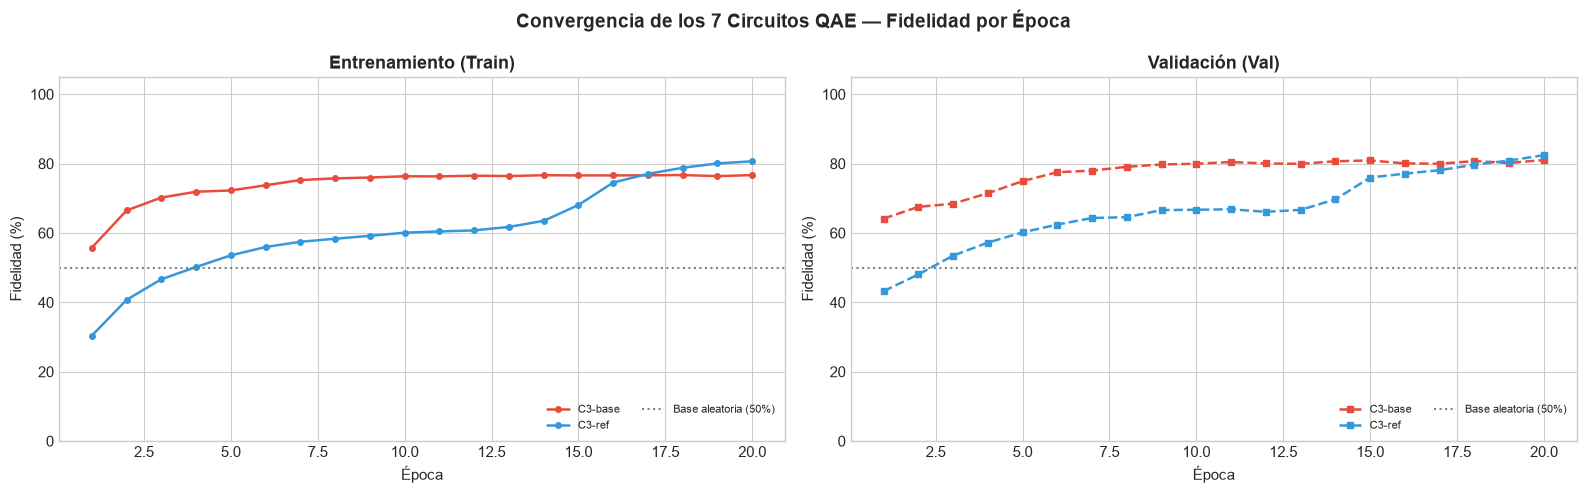

Guardado: convergencia_circuitos.png


In [9]:
# ==============================================================================
# CELDA 9: GRÁFICA DE CONVERGENCIA (Train + Val)
# ==============================================================================

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('Convergencia de los 7 Circuitos QAE — Fidelidad por Época',
             fontsize=14, fontweight='bold')
lb_val = list(resultados.values())[0]['lb']

for (nombre, res), col in zip(resultados.items(), COLORES):
    h   = res['history']
    eps = range(1, len(h['fid_tr']) + 1)
    lbl = nombre.split(':')[0]
    ax1.plot(eps, h['fid_tr'],  'o-',  color=col, label=lbl, lw=1.8, ms=4)
    ax2.plot(eps, h['fid_val'], 's--', color=col, label=lbl, lw=1.8, ms=4)

for ax, tit in [(ax1,'Entrenamiento (Train)'), (ax2,'Validación (Val)')]:
    ax.axhline(lb_val, color='gray', ls=':', lw=1.5, label=f'Base aleatoria ({lb_val:.0f}%)')
    ax.set_xlabel('Época'); ax.set_ylabel('Fidelidad (%)'); ax.set_ylim(0, 105)
    ax.set_title(tit, fontweight='bold')
    ax.legend(loc='lower right', fontsize=8, ncol=2)

plt.tight_layout()
plt.savefig('convergencia_circuitos.png', dpi=150, bbox_inches='tight')
plt.show()
print('Guardado: convergencia_circuitos.png')


---
## 🔍 7. Error de Reconstrucción: Fidelidad del Trash Qubit vs MSE

**¿Necesitamos un decoder explícito?** No es obligatorio. Aquí la explicación:

| Métrica | Fórmula | Significado |
|---------|---------|-------------|
| **Fidelidad** $F$ | $P(|0\rangle^M)$ | Qué tan bien se comprimió la info |
| **Error de reconstrucción** | $1 - F$ | Fracción de info perdida en los trash qubits |
| **MSE proxy** | $\overline{1-F}$ sobre el test set | Análogo al MSE input/output del decoder clásico |

La fidelidad del trash qubit **ya es** el error de reconstrucción cuántico.
`1 - F` mide exactamente cuánta información se 'fugó' a los qubits descartados.
Para conectar con el lenguaje del profesor, exponemos ambas métricas.


In [10]:
# ==============================================================================
# CELDA 10: EVALUACIÓN — FIDELIDAD, ERROR DE RECONSTRUCCIÓN, MSE PROXY Y MÉTRICAS DE DETECCIÓN
# ==============================================================================
from sklearn.metrics import (confusion_matrix, roc_auc_score, average_precision_score,
                             matthews_corrcoef)

N_EVAL = 50  # Muestras del test set para evaluación

# Anomalías sintéticas: inyectar perturbación espectral en componentes FFT
def hacer_anomalias(X, seed=7):
    np.random.seed(seed)
    Xan = X.copy()
    Xan[:, 10:25] += np.random.normal(0.4, 0.1, Xan[:, 10:25].shape)
    return l2(Xan)  # Re-normalizar tras perturbar

def metricas_deteccion(err_s, err_a, tau=None):
    """
    Métricas de detección. Clase positiva = ANOMALÍA (1), negativa = SANO (0).
    Score = error de reconstrucción (1 - F); se predice anomalía si score > tau.
    tau por defecto = percentil 95 del error en sanos (~5 % de falsos positivos esperados).
    Con N_sanos = N_anomalías el dataset de evaluación está balanceado, así que
    precisión y exactitud son interpretables sin corrección por prevalencia.
    """
    err_s = np.asarray(err_s, dtype=float); err_a = np.asarray(err_a, dtype=float)
    if tau is None:
        tau = np.percentile(err_s, 95)
    y_true = np.r_[np.zeros(len(err_s)), np.ones(len(err_a))].astype(int)
    score  = np.r_[err_s, err_a]
    y_pred = (score > tau).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    div = lambda a, b: float(a) / b if b > 0 else 0.0
    tpr  = div(tp, tp + fn)               # Recall / Sensibilidad / Tasa de detección
    tnr  = div(tn, tn + fp)               # Especificidad
    prec = div(tp, tp + fp)               # Precisión (VPP)
    return {
        'tau': float(tau), 'TP': int(tp), 'FP': int(fp), 'TN': int(tn), 'FN': int(fn),
        'TPR': tpr * 100, 'FPR': div(fp, fp + tn) * 100, 'TNR': tnr * 100, 'FNR': div(fn, fn + tp) * 100,
        'Precision': prec * 100, 'F1': div(2 * prec * tpr, prec + tpr) * 100,
        'Exactitud': div(tp + tn, tp + tn + fp + fn) * 100,
        'Exactitud_bal': (tpr + tnr) / 2 * 100,
        'MCC': float(matthews_corrcoef(y_true, y_pred)),
        'AUC_ROC': float(roc_auc_score(y_true, score)),
        'AP': float(average_precision_score(y_true, score)),
    }

X_anom = hacer_anomalias(X_test_q[:N_EVAL])

rows = []
scores = {}   # nombre -> (err_sanos, err_anomalias, tau) para matrices de confusión / ROC
for nombre, res in resultados.items():
    fid_fn = res['fid']
    W      = res['weights']

    # Fidelidad en sanos (test set)
    fids_s = [fid_fn(sv, W) for sv in X_test_q[:N_EVAL]]
    fid_s  = np.mean(fids_s) * 100      # En porcentaje
    mse_s  = 1.0 - np.mean(fids_s)      # MSE proxy = 1 - F (entre 0 y 1)

    # Fidelidad en anomalías sintéticas
    fids_a = [fid_fn(sv, W) for sv in X_anom]
    fid_a  = np.mean(fids_a) * 100

    err_s = [1 - f for f in fids_s]
    err_a = [1 - f for f in fids_a]
    m = metricas_deteccion(err_s, err_a)          # umbral P95 sobre sanos
    scores[nombre] = (np.array(err_s), np.array(err_a), m['tau'])

    rows.append({
        'Circuito':        nombre,
        'Fid. Sanos (%)':  round(fid_s, 2),
        'Fid. Anomalías (%)': round(fid_a, 2),
        'Separación (pp)': round(fid_s - fid_a, 2),
        'MSE Proxy (sanos)': round(mse_s, 4),
        'Detección (%)':   round(m['TPR'], 1),     # = TPR / Recall
        'FPR (%)':         round(m['FPR'], 1),
        'Precisión (%)':   round(m['Precision'], 1),
        'F1 (%)':          round(m['F1'], 1),
        'Exactitud (%)':   round(m['Exactitud'], 1),
        'Exact. Bal. (%)': round(m['Exactitud_bal'], 1),
        'MCC':             round(m['MCC'], 3),
        'AUC-ROC':         round(m['AUC_ROC'], 3),
        'AP':              round(m['AP'], 3),
        'TP': m['TP'], 'FP': m['FP'], 'TN': m['TN'], 'FN': m['FN'],
    })
    print(f'  {nombre:<28} sanos={fid_s:.1f}%  anom={fid_a:.1f}%  '
          f'sep={fid_s-fid_a:.1f}pp  detec={m["TPR"]:.0f}%  FPR={m["FPR"]:.0f}%  '
          f'F1={m["F1"]:.0f}%  AUC={m["AUC_ROC"]:.3f}')

df_eval = pd.DataFrame(rows).set_index('Circuito')
print("\n", df_eval.T.to_string())


  C3-base: StronglyEntangling  sanos=78.8%  anom=70.4%  sep=8.3pp  detec=0%  FPR=6%  F1=0%  AUC=0.805
  C3-ref: StronglyEntangling refinado sanos=83.2%  anom=41.7%  sep=41.5pp  detec=100%  FPR=6%  F1=97%  AUC=0.984

 Circuito            C3-base: StronglyEntangling  C3-ref: StronglyEntangling refinado
Fid. Sanos (%)                          78.7800                               83.200
Fid. Anomalías (%)                      70.4400                               41.740
Separación (pp)                          8.3300                               41.460
MSE Proxy (sanos)                        0.2122                                0.168
Detección (%)                            0.0000                              100.000
FPR (%)                                  6.0000                                6.000
Precisión (%)                            0.0000                               94.300
F1 (%)                                   0.0000                               97.100
Exactitud (%)     

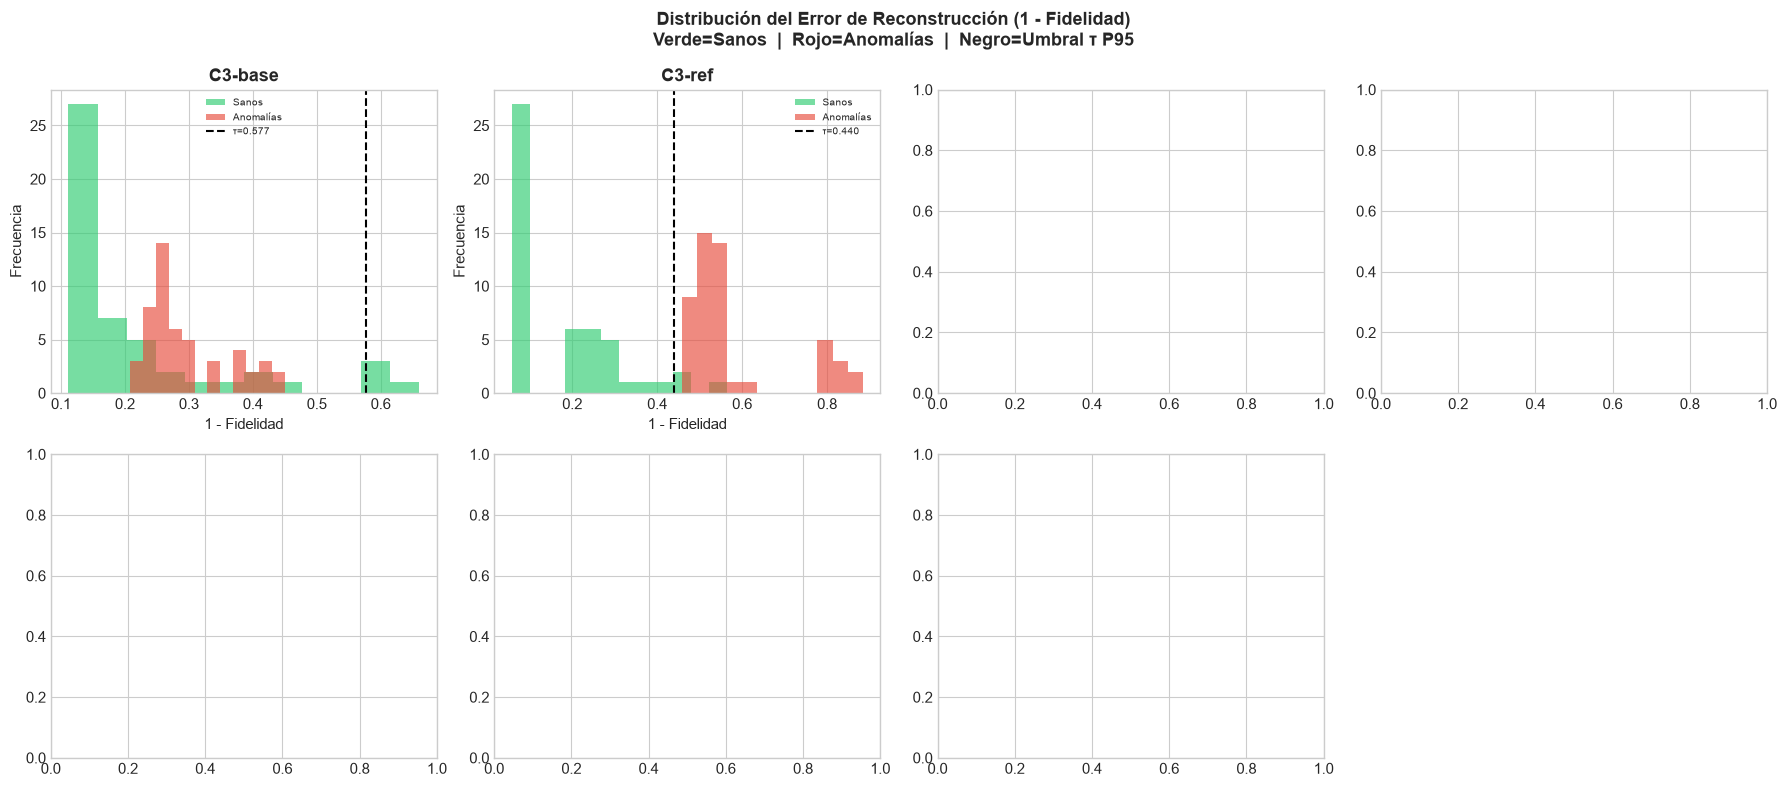

Guardado: histogramas_anomalias.png


In [11]:
# ==============================================================================
# CELDA 11: HISTOGRAMAS — DISTRIBUCIÓN DE ERRORES SANOS vs ANOMALÍAS
# ==============================================================================

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
fig.suptitle('Distribución del Error de Reconstrucción (1 - Fidelidad)\n'
             'Verde=Sanos  |  Rojo=Anomalías  |  Negro=Umbral τ P95',
             fontsize=13, fontweight='bold')

for idx, (nombre, res) in enumerate(resultados.items()):
    ax = axes[idx]
    fid_fn = res['fid']; W = res['weights']

    err_s = [1 - fid_fn(sv, W) for sv in X_test_q[:N_EVAL]]
    err_a = [1 - fid_fn(sv, W) for sv in X_anom]
    tau   = np.percentile(err_s, 95)

    ax.hist(err_s, bins=12, alpha=0.65, color='#2ecc71', label='Sanos')
    ax.hist(err_a, bins=12, alpha=0.65, color='#e74c3c', label='Anomalías')
    ax.axvline(tau, color='black', ls='--', lw=1.5, label=f'τ={tau:.3f}')
    ax.set_title(nombre.split(':')[0], fontweight='bold')
    ax.set_xlabel('1 - Fidelidad'); ax.set_ylabel('Frecuencia')
    ax.legend(fontsize=7)

axes[-1].axis('off')
plt.tight_layout()
plt.savefig('histogramas_anomalias.png', dpi=150, bbox_inches='tight')
plt.show()
print('Guardado: histogramas_anomalias.png')


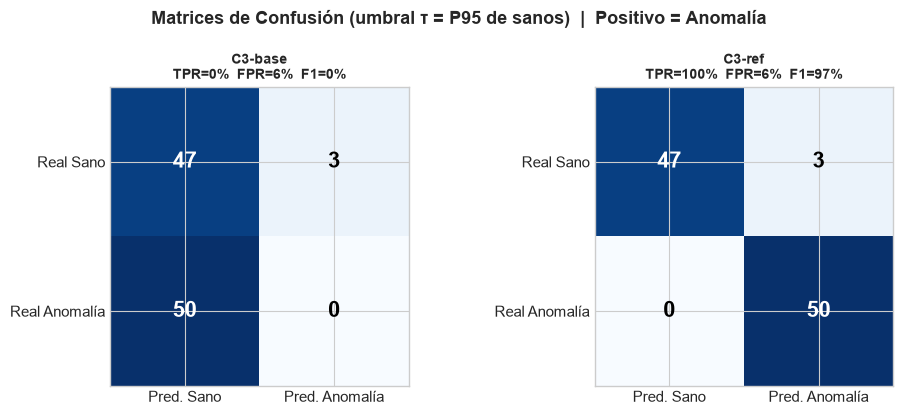

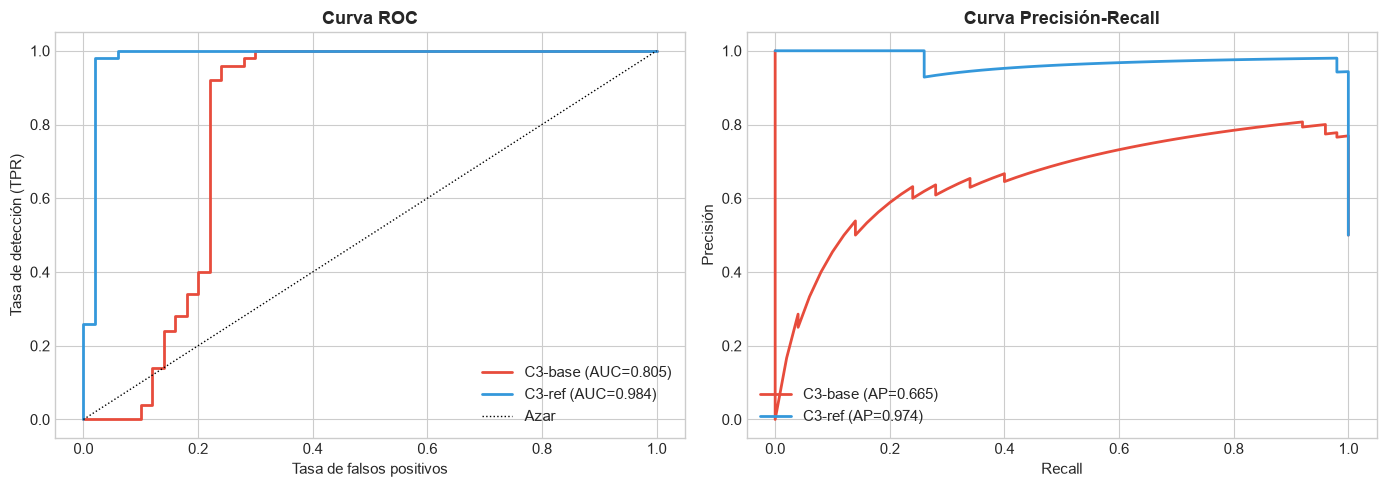

Guardado: matrices_confusion.png, roc_pr_circuitos.png


In [12]:
# ==============================================================================
# CELDA 11b: MATRICES DE CONFUSIÓN, CURVAS ROC Y PRECISIÓN-RECALL
# ==============================================================================
from sklearn.metrics import roc_curve, precision_recall_curve

n = len(scores)
fig, axes = plt.subplots(1, n, figsize=(5 * n, 4.2))
axes = np.atleast_1d(axes)
fig.suptitle('Matrices de Confusión (umbral τ = P95 de sanos)  |  Positivo = Anomalía',
             fontsize=13, fontweight='bold')
for ax, (nombre, (es, ea, tau)) in zip(axes, scores.items()):
    m  = metricas_deteccion(es, ea, tau)
    cm = np.array([[m['TN'], m['FP']], [m['FN'], m['TP']]])
    ax.imshow(cm, cmap='Blues')
    for r in range(2):
        for c in range(2):
            ax.text(c, r, str(cm[r, c]), ha='center', va='center', fontsize=16, fontweight='bold',
                    color='white' if cm[r, c] > cm.max() / 2 else 'black')
    ax.set_xticks([0, 1]); ax.set_xticklabels(['Pred. Sano', 'Pred. Anomalía'])
    ax.set_yticks([0, 1]); ax.set_yticklabels(['Real Sano', 'Real Anomalía'])
    ax.set_title(f"{nombre.split(':')[0]}\nTPR={m['TPR']:.0f}%  FPR={m['FPR']:.0f}%  F1={m['F1']:.0f}%",
                 fontsize=10, fontweight='bold')
plt.tight_layout()
plt.savefig('matrices_confusion.png', dpi=150, bbox_inches='tight')
plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for (nombre, (es, ea, tau)), col in zip(scores.items(), COLORES):
    y = np.r_[np.zeros(len(es)), np.ones(len(ea))]; s = np.r_[es, ea]
    fpr, tpr, _ = roc_curve(y, s)
    pr, rc, _   = precision_recall_curve(y, s)
    lbl = nombre.split(':')[0]
    ax1.plot(fpr, tpr, color=col, lw=2, label=f"{lbl} (AUC={roc_auc_score(y, s):.3f})")
    ax2.plot(rc, pr, color=col, lw=2, label=f"{lbl} (AP={average_precision_score(y, s):.3f})")
ax1.plot([0, 1], [0, 1], 'k:', lw=1, label='Azar')
ax1.set_xlabel('Tasa de falsos positivos'); ax1.set_ylabel('Tasa de detección (TPR)')
ax1.set_title('Curva ROC', fontweight='bold'); ax1.legend(loc='lower right')
ax2.set_xlabel('Recall'); ax2.set_ylabel('Precisión')
ax2.set_title('Curva Precisión-Recall', fontweight='bold'); ax2.legend(loc='lower left')
plt.tight_layout()
plt.savefig('roc_pr_circuitos.png', dpi=150, bbox_inches='tight')
plt.show()
print('Guardado: matrices_confusion.png, roc_pr_circuitos.png')


TABLA RESUMEN COMPLETA:
                                     Profundidad  Nº Parámetros  Total Puertas  Fid. Sanos (%)  Fid. Anomalías (%)  Separación (pp)  MSE Proxy (sanos)  Detección (%)  FPR (%)  Precisión (%)  F1 (%)  Exactitud (%)  Exact. Bal. (%)    MCC  AUC-ROC     AP  TP  FP  TN  FN
Circuito                                                                                                                                                                                                                                                                    
C3-base: StronglyEntangling                    2             42              2           78.78               70.44             8.33             0.2122            0.0      6.0            0.0     0.0           47.0             47.0 -0.176    0.805  0.665   0   3  47  50
C3-ref: StronglyEntangling refinado            2            126              2           83.20               41.74            41.46             0.1680          100.0    

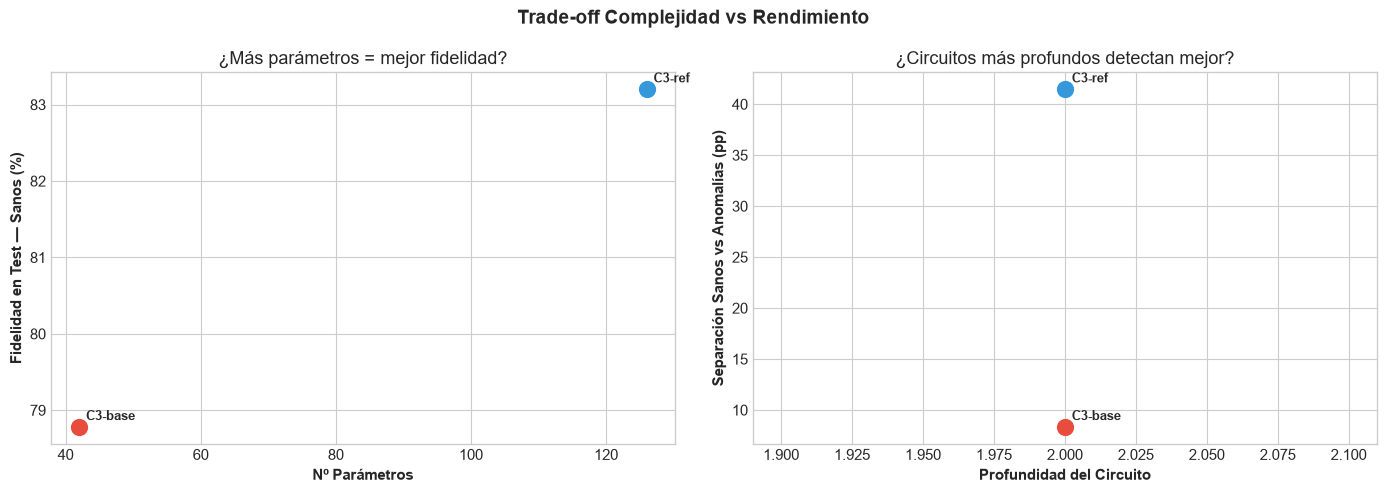

Guardado: scatter_complejidad.png


In [13]:
# ==============================================================================
# CELDA 12: TABLA RESUMEN + SCATTER — COMPLEJIDAD vs RENDIMIENTO
# ==============================================================================

df_final = df_comp[['Profundidad','Nº Parámetros','Total Puertas']].join(df_eval)
print("TABLA RESUMEN COMPLETA:")
print(df_final.to_string())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Trade-off Complejidad vs Rendimiento', fontsize=14, fontweight='bold')

for (nombre, col) in zip(df_final.index, COLORES):
    r   = df_final.loc[nombre]
    etq = nombre.split(':')[0]
    ax1.scatter(r['Nº Parámetros'], r['Fid. Sanos (%)'], color=col, s=130, zorder=5)
    ax1.annotate(etq, (r['Nº Parámetros'], r['Fid. Sanos (%)']),
                 textcoords='offset points', xytext=(5,5), fontsize=9, fontweight='bold')
    ax2.scatter(r['Profundidad'], r['Separación (pp)'], color=col, s=130, zorder=5)
    ax2.annotate(etq, (r['Profundidad'], r['Separación (pp)']),
                 textcoords='offset points', xytext=(5,5), fontsize=9, fontweight='bold')

ax1.set_xlabel('Nº Parámetros', fontweight='bold')
ax1.set_ylabel('Fidelidad en Test — Sanos (%)', fontweight='bold')
ax1.set_title('¿Más parámetros = mejor fidelidad?')
ax2.set_xlabel('Profundidad del Circuito', fontweight='bold')
ax2.set_ylabel('Separación Sanos vs Anomalías (pp)', fontweight='bold')
ax2.set_title('¿Circuitos más profundos detectan mejor?')

plt.tight_layout()
plt.savefig('scatter_complejidad.png', dpi=150, bbox_inches='tight')
plt.show()
print('Guardado: scatter_complejidad.png')


---
## 🧪 9. Búsqueda de la mejor configuración de C3 (en etapas)

Las celdas siguientes se ejecutan **en orden**; cada una depende de la anterior. Todo se controla desde los bloques de parámetros al inicio de cada celda.

| Celda | Qué hace | Costo aprox. |
|-------|----------|--------------|
| **13a** | Funciones, parámetros base, restricciones y fórmula del *score* | instantáneo |
| **13b** Etapa A | Barrido `n_layers × trash` (estructura por defecto) | ~15 configs × 3 semillas |
| **13c** Etapa B | Con las mejores de A, prueba `ranges × imprimitive` | ~16 configs × 3 semillas |
| **13d** Etapa C | Con la mejor de A+B, prueba `epochs × n_samp × lr` con 5 semillas | ~4–8 configs × 5 semillas |
| **13e** Validación final | Mejor config vs C3-base en el **split de test** (8 semillas), matrices de confusión, Pareto, y bloque `C3_CONFIG` listo para pegar | ~2 configs × 8 semillas |

**Metodología (evita sobreajustar la selección):** las etapas A–C evalúan en el split de **validación**; el split de **test** solo se usa en la validación final.

**Criterio de elección:** entre las configuraciones que cumplen `RESTRICCIONES` (fidelidad en sanos mínima, brecha train-sanos máxima = sobreentrenamiento, FPR máximo) se maximiza
`Score = (1 − W_FID)·F1 + W_FID·Fidelidad_sanos`.

**Cómo leer los resultados**
- `Fid sanos` alta = conserva información. Baja al subir `trash` (se comprime más).
- `TPR` (detección), `F1`, `MCC`, `AUC`, `AP` altos = separa bien sanos de anomalías sintéticas. `FPR` ronda 5 % por construcción (τ = P95 de sanos).
- `Gap tr-val` grande (> ~3 pp) = sobreentrenamiento. `F1 std` alta = resultado inestable entre semillas.
- Hallazgo previo (C1): más capas con 1 trash sube la fidelidad pero empeora la detección; `trash = 2` mejora mucho la separación.


In [14]:
# ==============================================================================
# CELDA 13a: BÚSQUEDA C3 — FUNCIONES, PARÁMETROS BASE Y CRITERIO DE SELECCIÓN
# ==============================================================================
import time, itertools

# ───────────────────────────── PARAMETROS ─────────────────────────────────────
PARAMETROS = dict(           # valores base de toda dimension que NO se barre en una etapa
    n_layers=4, trash=2, epochs=20, lr=0.12, batch=25, n_samp=100,
    ranges='default',        # 'default' | 'ring' | 'alt' | 'skip2'
    imprimitive='cnot',      # 'cnot' | 'cz'
)
RESTRICCIONES = dict(fid_min=80.0,   # Fidelidad minima en sanos (%)
                     gap_max=3.0,    # Brecha train - sanos maxima (pp) -> anti-sobreentrenamiento
                     fpr_max=10.0)   # FPR maximo (%)
W_FID = 0.3                  # Peso de la fidelidad en el score: (1-W)*F1 + W*Fid_sanos
N_EVAL_BUSQUEDA = 200        # Muestras sanas (y 200 anomalias) por evaluacion
# ──────────────────────────────────────────────────────────────────────────────

HISTORIAL, _CACHE = [], {}   # filas de todas las etapas / cache para no reentrenar

def entrenar_eval(cfg, seed, n_eval, split):
    """Entrena C3 con cfg y devuelve fidelidades + metricas de deteccion en `split` ('val' o 'test')."""
    np.random.seed(seed)
    ans, _ = hacer_ansatz_c3(cfg['ranges'], cfg['imprimitive'])
    dev = qml.device('default.qubit', wires=TOTAL_QUBITS)
    tw  = list(range(TOTAL_QUBITS - cfg['trash'], TOTAL_QUBITS))

    @qml.qnode(dev)
    def qn(sv, w):
        qml.AmplitudeEmbedding(sv, wires=range(TOTAL_QUBITS), normalize=False)
        ans(w, wires=range(TOTAL_QUBITS))
        return qml.probs(wires=tw)

    W  = pnp.random.uniform(0, 2*np.pi, size=(cfg['n_layers'], TOTAL_QUBITS, 3), requires_grad=True)
    Xd = X_train_q[:cfg['n_samp']]
    opt = qml.AdamOptimizer(stepsize=cfg['lr'])
    for ep in range(cfg['epochs']):
        perm = np.random.permutation(len(Xd))
        for i in range(0, len(Xd), cfg['batch']):
            B = pnp.array(Xd[perm[i:i+cfg['batch']]], requires_grad=False)
            W = opt.step(lambda w: 1.0 - pnp.mean(qn(B, w)[:, 0]), W)

    f  = lambda X: np.array(qn(pnp.array(X, requires_grad=False), W)[:, 0])
    Xs = (X_val_q if split == 'val' else X_test_q)[:n_eval]
    fs, fa = f(Xs), f(hacer_anomalias(Xs))
    m = metricas_deteccion(1 - fs, 1 - fa)          # definida en la celda 10 (tau = P95 de sanos)
    return dict(tr=f(Xd).mean()*100, san=fs.mean()*100, anom=fa.mean()*100, **m)

def evaluar_config(cfg, semillas, n_eval, split, etapa):
    """Promedia sobre semillas. Devuelve (fila, es_nueva)."""
    key = (tuple(sorted((k, str(v)) for k, v in cfg.items())), tuple(semillas), n_eval, split)
    if key in _CACHE:
        return _CACHE[key], False
    t0 = time.time()
    rs = [entrenar_eval(cfg, s, n_eval, split) for s in semillas]
    mu = lambda k: float(np.mean([r[k] for r in rs]))
    sd = lambda k: float(np.std([r[k] for r in rs]))
    row = dict(etapa=etapa, **{k: cfg[k] for k in PARAMETROS})
    row.update({
        'Params': cfg['n_layers'] * TOTAL_QUBITS * 3,
        'Fid train %': mu('tr'), 'Fid sanos %': mu('san'), 'Fid anom %': mu('anom'),
        'Gap tr-val': mu('tr') - mu('san'), 'Sep (pp)': mu('san') - mu('anom'),
        'TPR %': mu('TPR'), 'FPR %': mu('FPR'), 'Prec %': mu('Precision'),
        'F1 %': mu('F1'), 'F1 std': sd('F1'), 'Fid std': sd('san'),
        'Exact.Bal %': mu('Exactitud_bal'), 'MCC': mu('MCC'), 'AUC': mu('AUC_ROC'), 'AP': mu('AP'),
        'TP': mu('TP'), 'FP': mu('FP'), 'TN': mu('TN'), 'FN': mu('FN'),
        'Seg': time.time() - t0,
    })
    _CACHE[key] = row
    return row, True

def puntuar(df):
    df = df.copy()
    df['Score'] = (1 - W_FID) * df['F1 %'] + W_FID * df['Fid sanos %']
    df['Cumple'] = ((df['Fid sanos %'] >= RESTRICCIONES['fid_min']) &
                    (df['Gap tr-val'] <= RESTRICCIONES['gap_max']) &
                    (df['FPR %'] <= RESTRICCIONES['fpr_max']))
    return df.sort_values(['Cumple', 'Score'], ascending=False)

COLS_RESUMEN = ['n_layers', 'trash', 'ranges', 'imprimitive', 'epochs', 'n_samp', 'lr', 'Params',
                'Fid sanos %', 'Gap tr-val', 'TPR %', 'FPR %', 'F1 %', 'F1 std', 'MCC', 'AUC', 'Score', 'Cumple']

def ranking(df, top=10):
    d = puntuar(df)
    if not d['Cumple'].any():
        print('  AVISO: ninguna configuracion cumple RESTRICCIONES; se muestran las mejores por score.')
    print(d[COLS_RESUMEN].head(top).round(3).to_string(index=False))
    return d

def mejores(df, n, claves):
    """Top-n configuraciones distintas segun `claves` (sin repetir)."""
    return puntuar(df).drop_duplicates(subset=list(claves)).head(n)

def barrido(grid, base, semillas, etapa, n_eval=N_EVAL_BUSQUEDA, split='val'):
    claves = list(grid)
    combos = list(itertools.product(*[grid[k] for k in claves]))
    print(f'{etapa}: {len(combos)} configs x {len(semillas)} semillas = {len(combos)*len(semillas)} entrenamientos')
    filas, t_ini = [], time.time()
    for j, vals in enumerate(combos, 1):
        cfg = {**base, **dict(zip(claves, vals))}
        row, nueva = evaluar_config(cfg, semillas, n_eval, split, etapa)
        if nueva: HISTORIAL.append(row)
        filas.append(row)
        eta = (time.time() - t_ini) / j * (len(combos) - j)
        etiqueta = ' '.join(f'{k}={cfg[k]}' for k in claves)
        print(f"  [{j}/{len(combos)}] {etiqueta:<55} Fid={row['Fid sanos %']:.1f}% TPR={row['TPR %']:.0f}% "
              f"F1={row['F1 %']:.0f}% AUC={row['AUC']:.3f}  (ETA {eta/60:.1f} min)")
    return pd.DataFrame(filas)

def guardar_historial(ruta='busqueda_c3_historial.csv'):
    pd.DataFrame(HISTORIAL).to_csv(ruta, index=False)
    print(f'Historial guardado: {ruta} ({len(HISTORIAL)} configs)')

print('Funciones de busqueda listas. Continua con la celda 13b (Etapa A).')


Funciones de busqueda listas. Continua con la celda 13b (Etapa A).


In [15]:
# ==============================================================================
# CELDA 13b: ETAPA A — CAPAS x TRASH QUBITS (estructura por defecto)
# ==============================================================================
ETAPA_A    = dict(n_layers=[2, 3, 4, 6, 8], trash=[1, 2, 3])
SEMILLAS_A = [42, 1, 2]

df_A = barrido(ETAPA_A, PARAMETROS, SEMILLAS_A, etapa='A')
print('\nTOP Etapa A:')
_ = ranking(df_A, top=8)
guardar_historial()


A: 15 configs x 3 semillas = 45 entrenamientos
  [1/15] n_layers=2 trash=1                                      Fid=76.8% TPR=8% F1=14% AUC=0.793  (ETA 2.5 min)
  [2/15] n_layers=2 trash=2                                      Fid=53.6% TPR=30% F1=43% AUC=0.738  (ETA 2.1 min)
  [3/15] n_layers=2 trash=3                                      Fid=37.7% TPR=45% F1=56% AUC=0.846  (ETA 1.9 min)
  [4/15] n_layers=3 trash=1                                      Fid=90.0% TPR=75% F1=78% AUC=0.977  (ETA 1.9 min)
  [5/15] n_layers=3 trash=2                                      Fid=75.3% TPR=59% F1=67% AUC=0.927  (ETA 1.8 min)
  [6/15] n_layers=3 trash=3                                      Fid=53.2% TPR=69% F1=79% AUC=0.921  (ETA 1.6 min)
  [7/15] n_layers=4 trash=1                                      Fid=92.3% TPR=38% F1=40% AUC=0.789  (ETA 1.5 min)
  [8/15] n_layers=4 trash=2                                      Fid=77.2% TPR=90% F1=92% AUC=0.984  (ETA 1.4 min)
  [9/15] n_layers=4 trash=3       

In [ ]:
# ==============================================================================
# CELDA 13c: ETAPA B — RANGOS x COMPUERTA ENTRELAZANTE (sobre las mejores de A)
# ==============================================================================
N_TOP_B    = 2                     # cuantas (capas, trash) de la etapa A se refinan
ETAPA_B    = dict(ranges=['default', 'ring', 'alt', 'skip2'], imprimitive=['cnot', 'cz'])
SEMILLAS_B = [42, 1, 2]

tops_A = mejores(pd.DataFrame([r for r in HISTORIAL if r['etapa'] == 'A']), N_TOP_B, ['n_layers', 'trash'])
frames = []
for _, r in tops_A.iterrows():
    base = {**PARAMETROS, 'n_layers': int(r['n_layers']), 'trash': int(r['trash'])}
    print(f"\n>>> Base: n_layers={base['n_layers']} trash={base['trash']}")
    frames.append(barrido(ETAPA_B, base, SEMILLAS_B, etapa='B'))
df_B = pd.concat(frames, ignore_index=True)
print('\nTOP Etapa B:')
_ = ranking(df_B, top=8)
guardar_historial()


In [ ]:
# ==============================================================================
# CELDA 13d: ETAPA C — ÉPOCAS x REGISTROS x LR (sobre la mejor de A+B, 5 semillas)
# ==============================================================================
ETAPA_C    = dict(epochs=[20, 40], n_samp=[100, 200], lr=[0.12])   # agrega lr=[0.12, 0.06] para explorar mas
SEMILLAS_C = [42, 1, 2, 3, 4]

mejor = mejores(pd.DataFrame(HISTORIAL), 1, ['n_layers', 'trash', 'ranges', 'imprimitive']).iloc[0]
base_C = {**PARAMETROS, **{k: mejor[k] for k in ('n_layers', 'trash', 'ranges', 'imprimitive')}}
base_C['n_layers'] = int(base_C['n_layers']); base_C['trash'] = int(base_C['trash'])
print(f">>> Base C: {base_C}")
df_C = barrido(ETAPA_C, base_C, SEMILLAS_C, etapa='C')
print('\nTOP Etapa C:')
_ = ranking(df_C, top=8)
guardar_historial()


In [ ]:
# ==============================================================================
# CELDA 13e: VALIDACIÓN FINAL EN TEST — MEJOR CONFIG vs C3-BASE  (+ Pareto)
# ==============================================================================
SEMILLAS_FINAL = [42, 1, 2, 3, 4, 5, 6, 7]
N_EVAL_FINAL   = 500

d_all = puntuar(pd.DataFrame(HISTORIAL))
g = d_all.iloc[0]
GANADORA = {k: g[k] for k in PARAMETROS}
for k in ('n_layers', 'trash', 'epochs', 'n_samp', 'batch'): GANADORA[k] = int(GANADORA[k])
GANADORA['lr'] = float(GANADORA['lr'])
BASE = dict(n_layers=2, trash=1, epochs=20, lr=0.12, batch=25, n_samp=100, ranges='default', imprimitive='cnot')

print('Ganadora (segun validacion):', GANADORA)
print('Cumple restricciones en validacion:', bool(g['Cumple']))
filas = {}
for nombre, cfg in [('C3-base', BASE), ('C3-ganadora', GANADORA)]:
    row, nueva = evaluar_config(cfg, SEMILLAS_FINAL, N_EVAL_FINAL, 'test', 'FINAL')
    filas[nombre] = row
df_fin = pd.DataFrame(filas)
orden = ['n_layers', 'trash', 'ranges', 'imprimitive', 'epochs', 'n_samp', 'lr', 'Params',
         'Fid train %', 'Fid sanos %', 'Fid anom %', 'Gap tr-val', 'Sep (pp)',
         'TPR %', 'FPR %', 'Prec %', 'F1 %', 'F1 std', 'Exact.Bal %', 'MCC', 'AUC', 'AP', 'TP', 'FP', 'TN', 'FN']
print('\nRESULTADOS EN TEST (promedio de', len(SEMILLAS_FINAL), 'semillas):')
print(df_fin.loc[orden].to_string())

# Matrices de confusion promedio (positivo = anomalia)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, (nombre, row) in zip(axes, filas.items()):
    cm = np.array([[row['TN'], row['FP']], [row['FN'], row['TP']]])
    ax.imshow(cm, cmap='Blues')
    for r_ in range(2):
        for c_ in range(2):
            ax.text(c_, r_, f'{cm[r_, c_]:.0f}', ha='center', va='center', fontsize=15, fontweight='bold',
                    color='white' if cm[r_, c_] > cm.max() / 2 else 'black')
    ax.set_xticks([0, 1]); ax.set_xticklabels(['Pred. Sano', 'Pred. Anomalia'])
    ax.set_yticks([0, 1]); ax.set_yticklabels(['Real Sano', 'Real Anomalia'])
    ax.set_title(f"{nombre}\nTPR={row['TPR %']:.0f}%  FPR={row['FPR %']:.0f}%  F1={row['F1 %']:.0f}%", fontweight='bold')
plt.tight_layout(); plt.savefig('c3_confusion_final.png', dpi=150, bbox_inches='tight'); plt.show()

# Pareto fidelidad vs deteccion sobre todo el historial (validacion)
dh = pd.DataFrame(HISTORIAL)
fig, ax = plt.subplots(figsize=(8, 5.5))
for t, col in zip(sorted(dh['trash'].unique()), COLORES):
    s_ = dh[dh['trash'] == t]
    ax.scatter(s_['Fid sanos %'], s_['TPR %'], s=60, color=col, alpha=0.8, label=f'trash={t}', edgecolor='black', linewidth=0.4)
ax.scatter([g['Fid sanos %']], [g['TPR %']], s=260, marker='*', color='gold', edgecolor='black', zorder=5, label='Ganadora')
ax.set_xlabel('Fidelidad en sanos (%)'); ax.set_ylabel('Tasa de deteccion TPR (%)')
ax.set_title('Trade-off fidelidad vs deteccion (validacion, todas las etapas)', fontweight='bold'); ax.legend()
plt.tight_layout(); plt.savefig('c3_pareto_busqueda.png', dpi=150, bbox_inches='tight'); plt.show()
guardar_historial()

print('\n' + '=' * 78)
print('Pega este bloque en la CELDA 3 (reemplaza C3_CONFIG) y re-ejecuta las celdas 3 a 12:')
print('C3_CONFIG = dict(n_layers=%d, trash=%d, ranges=%r, imprimitive=%r,\n                 epochs=%d, lr=%s, n_samp=%d, batch=%d)' % (
    GANADORA['n_layers'], GANADORA['trash'], GANADORA['ranges'], GANADORA['imprimitive'],
    GANADORA['epochs'], GANADORA['lr'], GANADORA['n_samp'], GANADORA['batch']))


---
## 🎓 10. Conclusiones

- Ejecuta la celda **13e** y pega el bloque `C3_CONFIG` que imprime en la celda 3; luego re-ejecuta las celdas 3 a 12 para ver C3-ref con la configuración ganadora frente a C3-base.
- `1 - Fidelidad` del trash qubit es el error de reconstrucción cuántico; el **MSE Proxy** lo conecta con el lenguaje clásico.
- Registra los resultados finales en `modelo/C3/README.md`.
